In [ ]:
!pip install discopy==1.2.2

Local verification used preinstalled DisCoPy 1.2.2. Run this installation cell in Colab.


### SMSA 19.7 — Graphical calculus for quantum mechanics

Source: SMSA 7.8, 2026-11-05, `smsa.pdf`. References below use section and equation numbers. Read the corresponding SMSA passage first. Native DisCoPy drawings run **top to bottom**: this preview reverses SMSA’s usual vertical flow while preserving left-to-right tensor order. A coupon replaces SMSA’s specialized glyph where necessary. This notebook uses no user-defined functions or assertion checks.

Equations (19.54)–(19.57), (19.59): a native tensor box can hold a state, and `.dagger()` supplies complex conjugation. Choose $v=(1,i)$ so that the distinction from bilinear evaluation is visible. The unnormalised state has norm squared 2. Native box shapes replace SMSA’s triangular state coupons.

In [1]:
from discopy import tensor
H = tensor.Dim(2)
v = tensor.Box('v', tensor.Dim(), H, [1, 1j])
inner = v >> v.dagger()
value = inner.eval().array
print('v components:', v.eval().array)
print('v dagger components:', v.dagger().eval().array)
print('19.55 inner product:', value, '; expected:', 2, '; equal:', value == 2)
print('19.59 double dagger:', v.dagger().dagger().eval().array)
print('Expected:', v.eval().array)
print('Equal:', v.dagger().dagger().eval() == v.eval())

v components: [1.+0.j 0.+1.j]
v dagger components: [1.-0.j 0.-1.j]
19.55 inner product: (2+0j) ; expected: 2 ; equal: True
19.59 double dagger: [1.+0.j 0.+1.j]
Expected: [1.+0.j 0.+1.j]
Equal: True


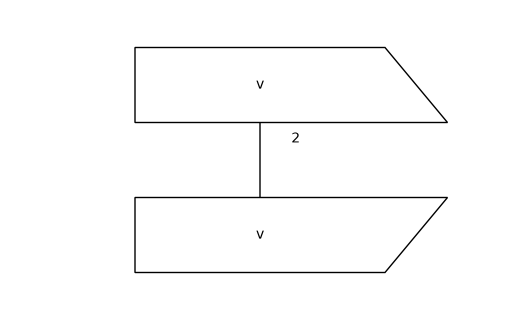

In [2]:
inner.draw(figsize=(5, 3))

### Two physical spins and one joint basis

This worked extension uses SMSA's product/entangled-state definition (§19.7.6), state diagrams (§19.7.10), adjoints (§§19.7.13–23), and the contractions of §17.6. The partial-trace test below is an added illustration, not a formula attributed to SMSA. Keep the two physical subsystems fixed: wire `A` is the first spin, wire `B` the second. Write the product basis in order $uu,ud,du,dd$.

Compare $|u,u\rangle$ with $|\mathrm{sing}\rangle=(|u,d\rangle-|d,u\rangle)/\sqrt2$. Their coefficient arrays have rows $a$ and columns $b$. Forming $|\Psi\rangle\langle\Psi|$ uses the **dagger**, including conjugation. Closing only the B wire gives
$$ (\rho_A)_{aa'}=\sum_b\Psi_{ab}\overline{\Psi_{a'b}}. $$
The A input and output stay open. This is a two-index matrix, not a scalar. Closing A afterwards gives its trace. For these normalized pure states, compare $\rho_A^2$ with $\rho_A$ and print the purity $\operatorname{tr}(\rho_A^2)$.


product amplitudes [a,b]:
 [[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]
Reduced diagram boundary: A -> A ; expected A -> A
rho_A, actual:
 [[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]] 
expected:
 [[1 0]
 [0 0]]
Agrees with expected and explicit sum: True True
rho_A squared:
 [[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]
Idempotent: True
Purity: (1+0j) ; expected: 1
Trace rho_A: (1+0j) ; expected: 1
singlet amplitudes [a,b]:
 [[ 0.        +0.j  0.70710678+0.j]
 [-0.70710678+0.j  0.        +0.j]]
Reduced diagram boundary: A -> A ; expected A -> A
rho_A, actual:
 [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]] 
expected:
 [[0.5 0. ]
 [0.  0.5]]
Agrees with expected and explicit sum: True True
rho_A squared:
 [[0.25+0.j 0.  +0.j]
 [0.  +0.j 0.25+0.j]]
Idempotent: False
Purity: (0.49999999999999983+0j) ; expected: 0.5
Trace rho_A: (0.9999999999999998+0j) ; expected: 1


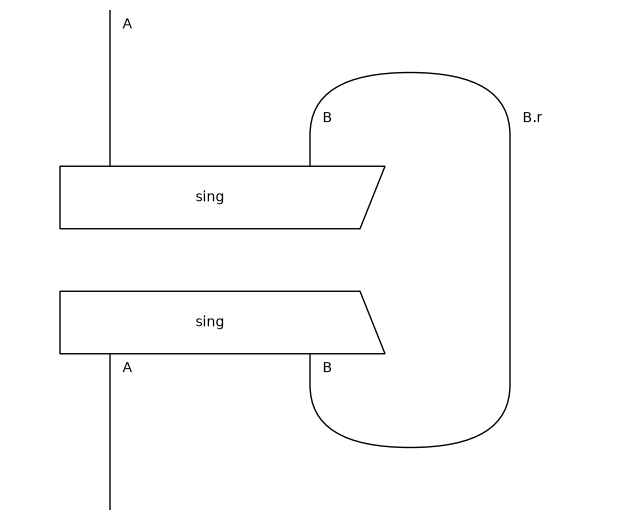

In [3]:
import numpy as np
from discopy import compact
from discopy.drawing import Equation
A, B, J = map(compact.Ty, ['A','B','joint label'])
product = compact.Box('uu', compact.Ty(), A @ B)
singlet = compact.Box('sing', compact.Ty(), A @ B)
product_amplitudes = np.array([[1,0],[0,0]], dtype=complex)
singlet_amplitudes = np.array([[0,1],[-1,0]], dtype=complex) / np.sqrt(2)
spin_model = tensor.Functor({A:2,B:2},
    {product:product_amplitudes,singlet:singlet_amplitudes},
    dom=compact.Category(),dtype=complex)
reduced_matrices = []
for name, state, amplitudes, expected_rho, expected_purity in [
    ('product', product, product_amplitudes, np.diag([1,0]), 1),
    ('singlet', singlet, singlet_amplitudes, np.eye(2)/2, .5)]:
    density = state.dagger() >> state
    reduced = density.trace(n=1)
    # Native operator arrays have input axes first; transpose for ordinary matrix rows.
    rho_A = spin_model(reduced).array.T
    explicit_sum = np.einsum('ab,cb->ac', amplitudes, amplitudes.conjugate())
    purity = spin_model(reduced >> reduced).array.trace()
    reduced_matrices.append(rho_A)
    print(name, 'amplitudes [a,b]:\n', amplitudes)
    print('Reduced diagram boundary:', reduced.dom, '->', reduced.cod, '; expected A -> A')
    print('rho_A, actual:\n', rho_A, '\nexpected:\n', expected_rho)
    print('Agrees with expected and explicit sum:', np.allclose(rho_A,expected_rho,atol=1e-12,rtol=0), np.allclose(rho_A,explicit_sum,atol=1e-12,rtol=0))
    print('rho_A squared:\n', rho_A @ rho_A)
    print('Idempotent:', np.allclose(rho_A @ rho_A,rho_A,atol=1e-12,rtol=0))
    print('Purity:', purity, '; expected:', expected_purity)
    print('Trace rho_A:', np.trace(rho_A), '; expected: 1')
singlet_reduced = (singlet.dagger() >> singlet).trace(n=1)
singlet_reduced.draw(figsize=(6,5))

### One nonzero joint-basis coefficient can still mean entanglement

Use the ordered joint basis $(\mathrm{sing},T_1,T_2,T_3)$, where
$$T_1=(ud+du)/\sqrt2,\quad T_2=(uu+dd)/\sqrt2,\quad T_3=(uu-dd)/\sqrt2.$$
Let $U$ have these four vectors as columns in the product basis. It converts joint-basis coefficients $c_\lambda$ to physical-spin amplitudes:
$$\Psi_{ab}=\sum_\lambda U_{ab,\lambda}c_\lambda.$$
The input wire `joint label` has dimension 4. Its label $\lambda$ enumerates basis vectors; it is **not** a pair of physical-spin indices. The two output wires `A,B` recover those indices. In particular $c=(1,0,0,0)$ describes the singlet, not $uu$.

This is a passive change of description of the same state. The use of a box for $U$ does not assert that a physical gate was applied to change the state.


U columns (sing,T1,T2,T3), rows (uu,ud,du,dd):
 [[ 0.        +0.j  0.        +0.j  0.70710678+0.j  0.70710678+0.j]
 [ 0.70710678+0.j  0.70710678+0.j  0.        +0.j  0.        +0.j]
 [-0.70710678+0.j  0.70710678+0.j  0.        +0.j  0.        +0.j]
 [ 0.        +0.j  0.        +0.j  0.70710678+0.j -0.70710678+0.j]]
U dagger U:
 [[ 1.00000000e+00+0.j -2.23711432e-17+0.j  0.00000000e+00+0.j
   0.00000000e+00+0.j]
 [-2.23711432e-17+0.j  1.00000000e+00+0.j  0.00000000e+00+0.j
   0.00000000e+00+0.j]
 [ 0.00000000e+00+0.j  0.00000000e+00+0.j  1.00000000e+00+0.j
  -2.23711432e-17+0.j]
 [ 0.00000000e+00+0.j  0.00000000e+00+0.j -2.23711432e-17+0.j
   1.00000000e+00+0.j]] 
expected: I4
Unitary: True
singlet joint coefficients: [1.+0.j 0.+0.j 0.+0.j 0.+0.j]
Recovered [a,b] amplitudes:
 [[ 0.        +0.j  0.70710678+0.j]
 [-0.70710678+0.j  0.        +0.j]] 
expected:
 [[ 0.        +0.j  0.70710678+0.j]
 [-0.70710678+0.j  0.        +0.j]]
Amplitudes match: True
Same physical rho_A:
 [[0.5+0.j 0. +0

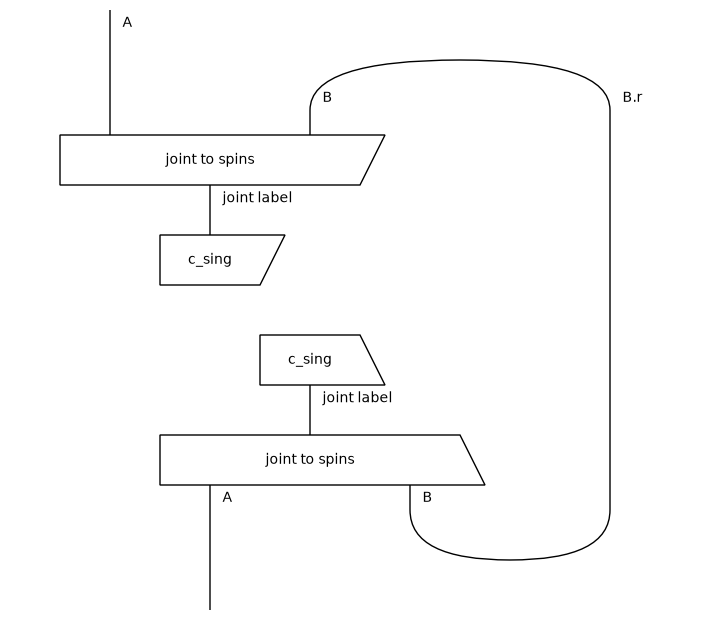

In [4]:
U = np.array([[0,0,1,1],[1,1,0,0],[-1,1,0,0],[0,0,1,-1]],dtype=complex)/np.sqrt(2)
basis_map = compact.Box('joint to spins', J, A @ B)
c_singlet = compact.Box('c_sing', compact.Ty(), J)
c_product = compact.Box('c_uu', compact.Ty(), J)
c_sing_values = np.array([1,0,0,0],dtype=complex)
c_product_values = np.array([0,0,1,1],dtype=complex)/np.sqrt(2)
joint_model = tensor.Functor({J:4,A:2,B:2},
    {basis_map:U.T.reshape(4,2,2),c_singlet:c_sing_values,c_product:c_product_values},
    dom=compact.Category(),dtype=complex)
print('U columns (sing,T1,T2,T3), rows (uu,ud,du,dd):\n', U)
print('U dagger U:\n', U.conjugate().T @ U, '\nexpected: I4')
print('Unitary:', np.allclose(U.conjugate().T @ U,np.eye(4),atol=1e-12,rtol=0))
joint_reduced_matrices = []
for label,c,expected_amplitudes,expected_rho in [
    ('singlet',c_singlet,singlet_amplitudes,np.eye(2)/2),
    ('product',c_product,product_amplitudes,np.diag([1,0]))]:
    physical = c >> basis_map
    reduced_joint = (physical.dagger() >> physical).trace(n=1)
    rho_joint = joint_model(reduced_joint).array.T
    joint_reduced_matrices.append(rho_joint)
    print(label,'joint coefficients:',joint_model(c).array)
    print('Recovered [a,b] amplitudes:\n',joint_model(physical).array,'\nexpected:\n',expected_amplitudes)
    print('Amplitudes match:',np.allclose(joint_model(physical).array,expected_amplitudes,atol=1e-12,rtol=0))
    print('Same physical rho_A:\n',rho_joint,'\nexpected:\n',expected_rho)
    print('Reduced matrix matches:',np.allclose(rho_joint,expected_rho,atol=1e-12,rtol=0))
from_joint_singlet = c_singlet >> basis_map
joint_singlet_reduced = (from_joint_singlet.dagger() >> from_joint_singlet).trace(n=1)
joint_singlet_reduced.draw(figsize=(7,6))

**A deliberately wrong contraction.** Reshaping $c=(1,0,0,0)$ into a $2\times2$ array and treating its axes as $a,b$ silently invents a different subsystem identification. The code below does that on purpose. It returns purity 1, which disagrees with the singlet's physical-spin purity $1/2$. The missing ingredient is $U$, not more nonzero coefficients.

Conversely, $uu$ has two nonzero joint-basis coefficients, $(0,0,1,1)/\sqrt2$, while remaining a product state. Counting nonzero coefficients in a joint basis is therefore not an entanglement test.


In [5]:
wrong_amplitudes = c_sing_values.reshape(2,2)
wrong_rho = wrong_amplitudes @ wrong_amplitudes.conjugate().T
print('Wrong reshape as physical amplitudes:\n',wrong_amplitudes)
print('Wrong reduced matrix:\n',wrong_rho,'; wrong purity:',np.trace(wrong_rho @ wrong_rho))
print('Matches physical singlet rho_A (expected False):',np.allclose(wrong_rho,joint_reduced_matrices[0],atol=1e-12,rtol=0))

Wrong reshape as physical amplitudes:
 [[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]]
Wrong reduced matrix:
 [[1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j]] ; wrong purity: (1+0j)
Matches physical singlet rho_A (expected False): False


### Three physical spins from a periodic matrix product state

SMSA 7.8, §19.7.8, (19.44), pp. 442–443 draws two auxiliary inputs and one physical output at each site. Its long bond joins the last site to the first. Keep that **periodic** connection for three spins. Our chosen example is
$$|\mathrm{GHZ}\rangle=(|u,u,u\rangle+|d,d,d\rangle)/\sqrt2.$$
The physical outputs are `A,B,C`, in that order. Auxiliary spaces `X,Y,Z` label bonds 12, 23 and 31, each of dimension 2. They are summed indices, not additional physical spins.

Choose a basis $e_0,e_1$ on each bond and its dual basis. Each native cap supplies the pair $\sum_{i=0}^1e_i\otimes e^i$ (or the reversed dual/primal order on the outer bond). The paired components are $\delta_{ij}$. Thus we spell out the pairing represented by SMSA's marked connections, rather than silently identifying a vector space with its dual. Local maps have types
$$M^{(1)}:Z^*\otimes X\to A,\qquad M^{(2)}:X^*\otimes Y\to B,\qquad M^{(3)}:Y^*\otimes Z\to C.$$
Their stored array axes are the two inputs followed by the output. Put $D_{ijk}=1$ when $i=j=k$ and 0 otherwise. Choose $M^{(1)}=D/\sqrt2$ and $M^{(2)}=M^{(3)}=D$. The displayed coefficients below are our example, not numbers supplied by SMSA.


M1 axes [z,x,a] shape (2, 2, 2) array:
 [[[0.70710678+0.j 0.        +0.j]
  [0.        +0.j 0.        +0.j]]

 [[0.        +0.j 0.        +0.j]
  [0.        +0.j 0.70710678+0.j]]]
M2 axes [x,y,b] shape (2, 2, 2) array:
 [[[1.+0.j 0.+0.j]
  [0.+0.j 0.+0.j]]

 [[0.+0.j 0.+0.j]
  [0.+0.j 1.+0.j]]]
M3 axes [y,z,c] shape (2, 2, 2) array:
 [[[1.+0.j 0.+0.j]
  [0.+0.j 0.+0.j]]

 [[0.+0.j 0.+0.j]
  [0.+0.j 1.+0.j]]]
Bond boundary: Z.r @ X @ X.r @ Y @ Y.r @ Z ; expected Z.r @ X @ X.r @ Y @ Y.r @ Z
Physical boundary: Ty() -> A @ B @ C ; expected unit -> A @ B @ C


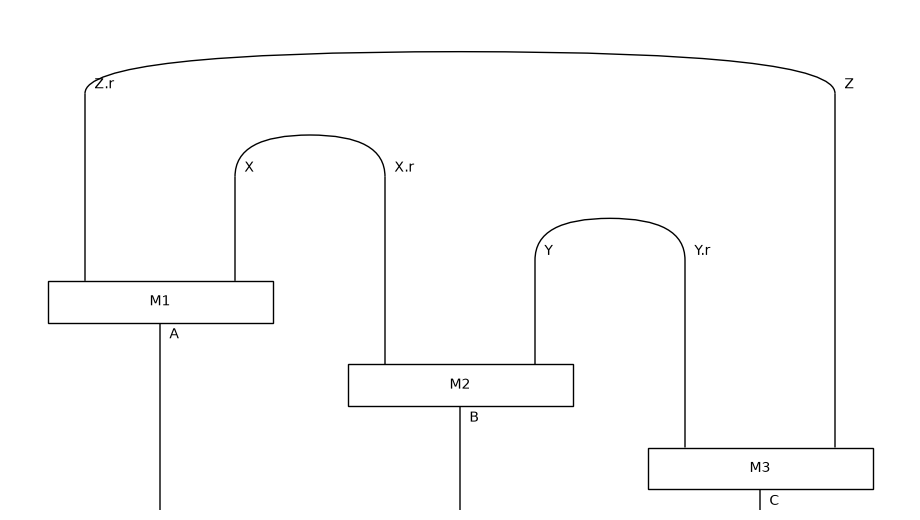

In [6]:
C = compact.Ty('C')
X, Y, Z = map(compact.Ty, ['X','Y','Z'])
M1 = compact.Box('M1', Z.r @ X, A)
M2 = compact.Box('M2', X.r @ Y, B)
M3 = compact.Box('M3', Y.r @ Z, C)
copy_array = np.zeros((2,2,2), dtype=complex)
copy_array[0,0,0] = copy_array[1,1,1] = 1
M1_array = copy_array / np.sqrt(2)
M2_array = copy_array.copy()
M3_array = copy_array.copy()
# Native caps retain the dual types; the outer cap closes bond 31.
mps_bonds = compact.Cap(Z.r,Z) >> (
    compact.Id(Z.r) @ compact.Cap(X,X.r) @ compact.Cap(Y,Y.r) @ compact.Id(Z))
mps = mps_bonds >> (M1 @ M2 @ M3)
bond_scale = compact.Box('1/sqrt2', compact.Ty(), compact.Ty())
mps_model = tensor.Functor({A:2,B:2,C:2,X:2,Y:2,Z:2},
    {M1:M1_array,M2:M2_array,M3:M3_array,bond_scale:1/np.sqrt(2)},
    dom=compact.Category(),dtype=complex)
for site, axes, values in [
    ('M1','[z,x,a]',M1_array),('M2','[x,y,b]',M2_array),('M3','[y,z,c]',M3_array)]:
    print(site,'axes',axes,'shape',values.shape,'array:\n',values)
print('Bond boundary:',mps_bonds.cod,'; expected Z.r @ X @ X.r @ Y @ Y.r @ Z')
print('Physical boundary:',mps.dom,'->',mps.cod,'; expected unit -> A @ B @ C')
mps.draw(figsize=(9,5))


Read the native picture from top to bottom. The long outer cap is the last-to-first bond of (19.44). Only the three physical wires leave the network. The array calculation is the same contraction:
$$\Psi_{abc}=\sum_{x,y,z=0}^1 M^{(1)}_{zxa}M^{(2)}_{xyb}M^{(3)}_{yzc}.$$
Print the eight amplitudes in order $uuu,uud,udu,udd,duu,dud,ddu,ddd$. Then keep A open and trace out the physical B and C wires, just as for the two-spin example. This checks the physical state after the auxiliary indices have already disappeared.


In [7]:
mps_amplitudes = mps_model(mps).array
mps_explicit = np.einsum('zxa,xyb,yzc->abc',M1_array,M2_array,M3_array)
ghz_expected = np.array([1,0,0,0,0,0,0,1],dtype=complex).reshape(2,2,2)/np.sqrt(2)
print('Amplitudes [a,b,c], flattened uuu through ddd:',mps_amplitudes.reshape(8))
print('Expected:',ghz_expected.reshape(8))
print('Native network matches explicit contraction:',np.allclose(mps_amplitudes,mps_explicit,atol=1e-12,rtol=0))
print('Native network matches GHZ:',np.allclose(mps_amplitudes,ghz_expected,atol=1e-12,rtol=0))
mps_norm = mps_model(mps >> mps.dagger()).array
mps_reduced = (mps.dagger() >> mps).trace(n=2)
mps_rho_A = mps_model(mps_reduced).array.T
print('Squared norm:',mps_norm,'; expected: 1')
print('Reduced boundary:',mps_reduced.dom,'->',mps_reduced.cod,'; expected A -> A')
print('rho_A:\n',mps_rho_A,'\nexpected:\n',np.eye(2)/2)
print('rho_A matches:',np.allclose(mps_rho_A,np.eye(2)/2,atol=1e-12,rtol=0))
print('Purity:',np.trace(mps_rho_A @ mps_rho_A),'; expected: 1/2')


Amplitudes [a,b,c], flattened uuu through ddd: [0.70710678+0.j 0.        +0.j 0.        +0.j 0.        +0.j
 0.        +0.j 0.        +0.j 0.        +0.j 0.70710678+0.j]
Expected: [0.70710678+0.j 0.        +0.j 0.        +0.j 0.        +0.j
 0.        +0.j 0.        +0.j 0.        +0.j 0.70710678+0.j]
Native network matches explicit contraction: True
Native network matches GHZ: True
Squared norm: (0.9999999999999998+0j) ; expected: 1
Reduced boundary: A -> A ; expected A -> A
rho_A:
 [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]] 
expected:
 [[0.5 0. ]
 [0.  0.5]]
rho_A matches: True
Purity: (0.4999999999999998+0j) ; expected: 1/2


**A normalization control.** The caps above are the unnormalised dual-basis sums. If we instead divide each of the three bonds by $\sqrt2$ while keeping the same site arrays, the resulting state is too small. Scalars commute with this contraction, so three scalar coupons before the network implement that change directly. Its squared norm is $1/8$, not 1. A normalized bond convention is possible, but its site coefficients must be adjusted consistently.

This is one exact three-spin construction, checked numerically with the printed arrays. It illustrates how a bond dimension of 2 can represent an entangled state. General statements about approximation of ground states, or the dimension and geometry of the family of MPS, are outside this example.


In [8]:
mps_wrong_bond_norm = (bond_scale @ bond_scale @ bond_scale) >> mps
wrong_bond_norm = mps_model(mps_wrong_bond_norm >> mps_wrong_bond_norm.dagger()).array
print('Squared norm with three newly normalized bonds:',wrong_bond_norm,'; expected: 1/8')
print('Matches 1/8:',np.allclose(wrong_bond_norm,1/8,atol=1e-12,rtol=0))
print('Still normalized (expected False):',np.allclose(wrong_bond_norm,1,atol=1e-12,rtol=0))


Squared norm with three newly normalized bonds: (0.12499999999999992+0j) ; expected: 1/8
Matches 1/8: True
Still normalized (expected False): False


### The dagger laws (19.59), (19.63)–(19.65) and $c^\dagger=c^{-1}$

The library's `.dagger()` on a tensor box is the conjugate transpose, and on a composite it reverses the order and daggers each box, which is (19.59). SMSA draws a map as an asymmetric coupon (19.60) and its adjoint as the mirror image (19.61); the library draws a daggered box with the opposite slant, so the figures below carry no dagger symbol either. Boxes `f` and `g` are rectangular complex examples chosen here. For (19.65) the two sides print as different layered expressions, because the library writes a parallel pair in layers; the interchange law of §17.1 identifies them, and their arrays agree. The braiding of a symmetric monoidal dagger category (19.7.31) is unitary: the dagger of the swap is the swap back.

In [9]:
import numpy as np
from discopy.drawing import Equation
D2, D3 = tensor.Dim(2), tensor.Dim(3)
f = tensor.Box('f', D2, D3, np.array([[1, 2j, 0], [3, 1, -1j]]))
g = tensor.Box('g', D3, D2, np.array([[1, 1j], [0, 2], [1, 0]]))
print('f array, input axis first:\n', f.eval().array)
print('f dagger array:\n', f.dagger().eval().array)
print('Equals the conjugate transpose:', np.allclose(f.dagger().eval().array, f.eval().array.conj().T))
print('(19.59) (g o f) dagger as a diagram:', (f >> g).dagger(), '; g dagger then f dagger:', g.dagger() >> f.dagger())
print('Same expression:', str((f >> g).dagger()) == str(g.dagger() >> f.dagger()), '; same arrays:', np.allclose((f >> g).dagger().eval().array, (g.dagger() >> f.dagger()).eval().array))
print('(19.59) identity dagger:', tensor.Id(D2).dagger(), '; equals the identity:', tensor.Id(D2).dagger() == tensor.Id(D2))
print('(19.65) (f ⊗ g) dagger:', (f @ g).dagger(), '\n        f dagger ⊗ g dagger:', f.dagger() @ g.dagger())
print('Same arrays:', np.allclose((f @ g).dagger().eval().array, (f.dagger() @ g.dagger()).eval().array))
swap = tensor.Swap(D2, D3)
print('Braiding dagger:', swap.dagger(), '; equals the inverse swap:', swap.dagger() == tensor.Swap(D3, D2))
print('swap then its dagger is the identity on Dim(2) ⊗ Dim(3):', np.allclose((swap >> swap.dagger()).eval().array, tensor.Id(D2 @ D3).eval().array))


f array, input axis first:
 [[ 1.+0.j  0.+2.j  0.+0.j]
 [ 3.+0.j  1.+0.j -0.-1.j]]
f dagger array:
 [[ 1.-0.j  3.-0.j]
 [ 0.-2.j  1.-0.j]
 [ 0.-0.j -0.+1.j]]
Equals the conjugate transpose: True
(19.59) (g o f) dagger as a diagram: g[::-1] >> f[::-1] ; g dagger then f dagger: g[::-1] >> f[::-1]
Same expression: True ; same arrays: True
(19.59) identity dagger: Id(Dim(2)) ; equals the identity: True
(19.65) (f ⊗ g) dagger: Dim(3) @ g[::-1] >> f[::-1] @ Dim(3) 
        f dagger ⊗ g dagger: f[::-1] @ Dim(2) >> Dim(2) @ g[::-1]
Same arrays: True
Braiding dagger: Swap(Dim(3), Dim(2)) ; equals the inverse swap: True
swap then its dagger is the identity on Dim(2) ⊗ Dim(3): True


A unitary (19.63) satisfies $u^\dagger u=\mathrm{id}$ and $u u^\dagger=\mathrm{id}$; the Hadamard matrix of §19.8 is the example. An isometry satisfies only the first equation: the box `iso` below sends $\mathbb C^2$ onto a plane in $\mathbb C^3$, and `iso.dagger() >> iso` is a projector of rank $2$, not the identity. A projector (19.64) is a self-adjoint idempotent; the drawn example is $p_0=e_0\circ r_0$ of `smsa_15_01.ipynb`, the projector onto the first basis vector.

(19.63) u dagger then u :
 [[ 1. -0.]
 [-0.  1.]] ; identity: True
(19.63) u then u dagger :
 [[ 1. -0.]
 [-0.  1.]] ; identity: True
Isometry, iso then iso dagger:
 [[1. 0.]
 [0. 1.]] ; identity on Dim(2): True
iso dagger then iso:
 [[1.  0.  0. ]
 [0.  0.5 0.5]
 [0.  0.5 0.5]] ; identity on Dim(3) (expected False): False ; idempotent: True
(19.64) p0 then p0:
 [[1 0]
 [0 0]] ; equals p0: True ; self-adjoint: True


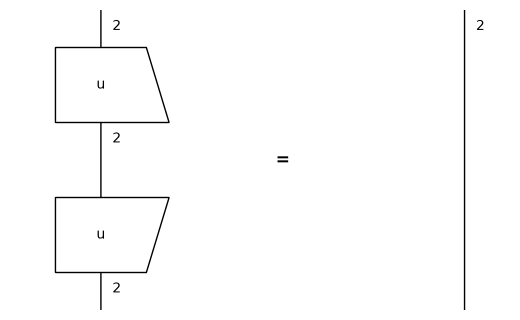

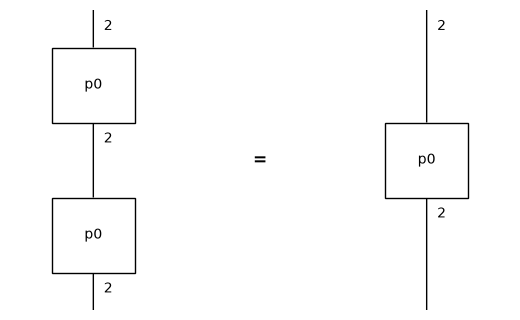

In [10]:
u = tensor.Box('u', D2, D2, np.array([[1, 1], [1, -1]]) / np.sqrt(2))
for label, side in [('u dagger then u', u.dagger() >> u), ('u then u dagger', u >> u.dagger())]:
    print('(19.63)', label, ':\n', np.round(side.eval().array, 12), '; identity:', np.allclose(side.eval().array, np.eye(2), atol=1e-12))
Equation(u >> u.dagger(), tensor.Id(D2), symbol='=').draw(figsize=(5, 3))
iso = tensor.Box('iso', D2, D3, np.array([[1, 0, 0], [0, 1, 1]]) / np.array([[1], [np.sqrt(2)]]))
print('Isometry, iso then iso dagger:\n', np.round((iso >> iso.dagger()).eval().array, 12), '; identity on Dim(2):', np.allclose((iso >> iso.dagger()).eval().array, np.eye(2), atol=1e-12))
partial = (iso.dagger() >> iso).eval().array
print('iso dagger then iso:\n', np.round(partial, 12), '; identity on Dim(3) (expected False):', np.allclose(partial, np.eye(3), atol=1e-12), '; idempotent:', np.allclose(partial @ partial, partial, atol=1e-12))
p0 = tensor.Box('p0', D2, D2, np.diag([1, 0]))
print('(19.64) p0 then p0:\n', (p0 >> p0).eval().array, '; equals p0:', np.allclose((p0 >> p0).eval().array, p0.eval().array), '; self-adjoint:', np.allclose(p0.dagger().eval().array, p0.eval().array))
Equation(p0 >> p0, p0, symbol='=').draw(figsize=(5, 3))


**Scope.** These are finite-dimensional selected-basis calculations on the displayed arrays. The dagger laws are library behaviour verified on the examples; whether a given map is unitary or a projector is decided by evaluating its arrays, as the isometry control shows. The unitarity of associators and unitors required in 19.7.30 is the triangle and pentagon material of `smsa_19_03.ipynb` and `smsa_19_04.ipynb`.